In [2]:
from feed import get_data
from utils import resample_df, get_dates

symbol = "BTCUSDT"

In [2]:
df = get_data(
    "BTCUSDT",
    20260101,
    20260105
)
df

,symbol,date,time,open,high,low,close,volume
0,BTCUSDT,20260101,0,87648.21,87648.22,87632.74,87648.00,4.08049
1,BTCUSDT,20260101,60,87648.00,87686.79,87647.99,87686.79,8.53093
2,BTCUSDT,20260101,120,87686.78,87686.79,87679.28,87682.91,4.08878
3,BTCUSDT,20260101,180,87682.91,87701.91,87682.91,87701.90,1.26772
4,BTCUSDT,20260101,240,87701.91,87701.91,87701.90,87701.91,0.47668
...,...,...,...,...,...,...,...,...
5755,BTCUSDT,20260104,86100,91430.88,91437.18,91399.99,91399.99,10.07719
5756,BTCUSDT,20260104,86160,91400.00,91418.34,91399.99,91418.34,25.20174
5757,BTCUSDT,20260104,86220,91418.34,91450.00,91413.12,91449.99,3.94739
5758,BTCUSDT,20260104,86280,91450.00,91481.06,91439.02,91481.05,3.06548


In [3]:
resampled = resample_df(df, 60*5)

resampled

,date,time,open,high,low,close,volume
0,20260101,0,87648.21,87701.91,87632.74,87701.91,18.44460
1,20260101,300,87701.91,87816.00,87701.90,87764.06,57.78717
2,20260101,600,87764.06,87764.07,87742.61,87742.61,9.86578
3,20260101,900,87742.62,87760.19,87742.61,87760.19,9.47001
4,20260101,1200,87760.19,87774.00,87760.18,87773.97,4.62578
...,...,...,...,...,...,...,...
1147,20260104,84900,91388.03,91437.44,91300.32,91360.00,17.11498
1148,20260104,85200,91360.00,91360.00,91300.00,91320.39,22.50083
1149,20260104,85500,91320.39,91372.76,91269.69,91332.38,30.08858
1150,20260104,85800,91332.37,91461.07,91332.37,91430.88,25.27663


In [1]:
from utils import compute_rsi

compute_rsi([12, 11, 34, 21])

[0, 0, 23, 0]
[0, -1, 0, -13]


In [3]:
start_date, end_date = get_dates(500)

df = get_data(symbol, start_date, end_date, "6h")

df

,symbol,date,time,open,high,low,close,volume
0,BTCUSDT,20250514,0,104103.72,104115.86,103453.26,103896.71,3945.42407
1,BTCUSDT,20250514,21600,103896.70,104145.00,102875.22,103944.93,4703.31130
2,BTCUSDT,20250514,43200,103944.93,104356.95,102602.05,103246.79,6272.84550
3,BTCUSDT,20250514,64800,103246.78,103720.44,103029.45,103507.82,1531.32723
4,BTCUSDT,20250515,0,103507.83,103866.51,102336.70,102375.31,2668.98515
...,...,...,...,...,...,...,...,...
1995,BTCUSDT,20260924,64800,84110.00,84660.00,83888.00,84410.24,2982.87383
1996,BTCUSDT,20260925,0,84410.24,84888.00,84061.22,84194.01,2933.37845
1997,BTCUSDT,20260925,21600,84194.00,85255.00,83750.50,84582.64,5471.45068
1998,BTCUSDT,20260925,43200,84582.64,84704.00,83183.00,83785.11,7550.32664


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df["datetime"] = (
    pd.to_datetime(
        df["date"].astype(str),
        format="%Y%m%d"
    )
    + pd.to_timedelta(df["time"], unit="s")
)

df

,symbol,date,time,open,high,low,close,volume,datetime
0,BTCUSDT,20250514,0,104103.72,104115.86,103453.26,103896.71,3945.42407,2025-05-14 00:00:00
1,BTCUSDT,20250514,21600,103896.70,104145.00,102875.22,103944.93,4703.31130,2025-05-14 06:00:00
2,BTCUSDT,20250514,43200,103944.93,104356.95,102602.05,103246.79,6272.84550,2025-05-14 12:00:00
3,BTCUSDT,20250514,64800,103246.78,103720.44,103029.45,103507.82,1531.32723,2025-05-14 18:00:00
4,BTCUSDT,20250515,0,103507.83,103866.51,102336.70,102375.31,2668.98515,2025-05-15 00:00:00
...,...,...,...,...,...,...,...,...,...
1995,BTCUSDT,20260924,64800,84110.00,84660.00,83888.00,84410.24,2982.87383,2026-09-24 18:00:00
1996,BTCUSDT,20260925,0,84410.24,84888.00,84061.22,84194.01,2933.37845,2026-09-25 00:00:00
1997,BTCUSDT,20260925,21600,84194.00,85255.00,83750.50,84582.64,5471.45068,2026-09-25 06:00:00
1998,BTCUSDT,20260925,43200,84582.64,84704.00,83183.00,83785.11,7550.32664,2026-09-25 12:00:00


In [6]:
import utils


window = 10
source = "close"

for i in range(window - 1, len(df)):

    prices = df[source].iloc[i-window+1:i+1].tolist()
    times = list(range(window))

    regression = utils.regression_line(prices, times)

    df.loc[i, "regression_m"] = regression.m
    df.loc[i, "regression_b"] = regression.b
    df.loc[i, "r_squared"] = regression.r_squared

df = df.dropna(subset=["regression_m", "regression_b", "r_squared"])

df

,symbol,date,time,open,high,low,close,volume,datetime,regression_m,regression_b,r_squared
9,BTCUSDT,20250516,21600,103898.52,104190.48,103100.49,103651.71,4580.33990,2025-05-16 06:00:00,8.680545,103423.472545,0.001821
10,BTCUSDT,20250516,43200,103651.72,104550.33,103343.07,103867.96,5162.42812,2025-05-16 12:00:00,59.739636,103190.831636,0.086850
11,BTCUSDT,20250516,64800,103867.96,104094.90,103397.50,103463.90,1769.76367,2025-05-16 18:00:00,92.322242,102996.106909,0.224553
12,BTCUSDT,20250517,0,103463.90,103709.86,102612.50,103342.79,3419.91350,2025-05-17 00:00:00,77.586848,103072.016182,0.159783
13,BTCUSDT,20250517,21600,103342.79,103640.14,102753.67,102994.17,3478.15455,2025-05-17 06:00:00,60.074182,103099.458182,0.091426
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,BTCUSDT,20260924,64800,84110.00,84660.00,83888.00,84410.24,2982.87383,2026-09-24 18:00:00,-327.768606,86439.134727,0.748516
1996,BTCUSDT,20260925,0,84410.24,84888.00,84061.22,84194.01,2933.37845,2026-09-25 00:00:00,-262.706727,85908.733273,0.612885
1997,BTCUSDT,20260925,21600,84194.00,85255.00,83750.50,84582.64,5471.45068,2026-09-25 06:00:00,-171.756061,85336.863273,0.355291
1998,BTCUSDT,20260925,43200,84582.64,84704.00,83183.00,83785.11,7550.32664,2026-09-25 12:00:00,-85.435576,84677.331091,0.201472


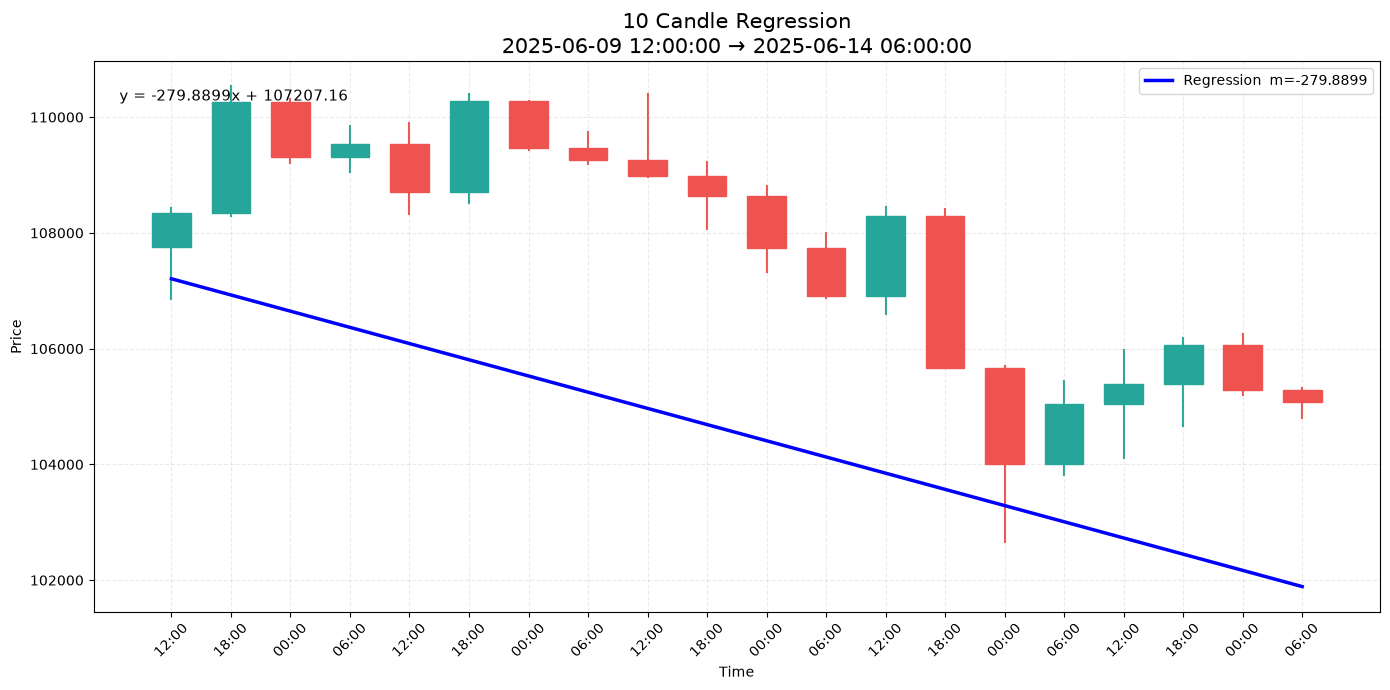

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def plot_regression_window(dataset, end_idx, window=10):

    start_idx = end_idx - window + 1
    data = dataset.iloc[start_idx:end_idx + 1].copy()

    # x positions: 0, 1, 2, ... 9
    x = np.arange(window)

    # --------------------------------------------------
    # Get regression values for THIS 10-candle window
    # --------------------------------------------------

    m = data["regression_m"].iloc[-1]
    b = data["regression_b"].iloc[-1]
    r_squared = data["r_squared"].iloc[-1]

    regression_y = m * x + b

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    fig, ax = plt.subplots(figsize=(14, 7))

    candle_width = 0.65

    for i, (_, row) in enumerate(data.iterrows()):

        open_price = row["open"]
        high_price = row["high"]
        low_price = row["low"]
        close_price = row["close"]

        # ----------------------------------------------
        # Candle color
        # ----------------------------------------------

        if close_price >= open_price:
            candle_color = "#26a69a"   # green
        else:
            candle_color = "#ef5350"   # red

        # ----------------------------------------------
        # Wick
        # ----------------------------------------------

        ax.plot(
            [i, i],
            [low_price, high_price],
            color=candle_color,
            linewidth=1.5,
            zorder=1
        )

        # ----------------------------------------------
        # Candle body
        # ----------------------------------------------

        body_low = min(open_price, close_price)
        body_high = max(open_price, close_price)
        body_height = body_high - body_low

        # Do not make doji candles invisible
        if body_height == 0:
            body_height = 0.1

        candle = Rectangle(
            (
                i - candle_width / 2,
                body_low
            ),
            candle_width,
            body_height,
            facecolor=candle_color,
            edgecolor=candle_color,
            linewidth=1,
            zorder=2
        )

        ax.add_patch(candle)

    # --------------------------------------------------
    # Regression line
    # --------------------------------------------------

    ax.plot(
        x,
        regression_y,
        color="blue",
        linewidth=2.5,
        label=f"Regression  m={m:.4f}",
        zorder=3
    )

    # --------------------------------------------------
    # X axis
    # --------------------------------------------------

    ax.set_xticks(x)

    ax.set_xticklabels(
        data["datetime"].dt.strftime("%H:%M"),
        rotation=45
    )

    # --------------------------------------------------
    # Labels
    # --------------------------------------------------

    ax.set_title(
        f"10 Candle Regression\n"
        f"{data['datetime'].iloc[0]} → "
        f"{data['datetime'].iloc[-1]}",
        fontsize=15
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Price")

    # --------------------------------------------------
    # Grid
    # --------------------------------------------------

    ax.grid(
        True,
        alpha=0.25,
        linestyle="--"
    )

    # --------------------------------------------------
    # Regression equation
    # --------------------------------------------------

    ax.text(
        0.02,
        0.95,
        f"y = {m:.4f}x + {b:.2f}",
        transform=ax.transAxes,
        fontsize=11,
        verticalalignment="top"
    )

    ax.legend()

    plt.tight_layout()
    plt.show()



plot_regression_window(
    df,
    end_idx=116,
    window=20
)

In [8]:
from utils import add_regression_lines

research = add_regression_lines(df)

research

,symbol,date,time,open,high,low,close,volume,datetime,regression_m,regression_b,r_squared
9,BTCUSDT,20250516,21600,103898.52,104190.48,103100.49,103651.71,4580.33990,2025-05-16 06:00:00,64.254788,103297.155455,0.134061
10,BTCUSDT,20250516,43200,103651.72,104550.33,103343.07,103867.96,5162.42812,2025-05-16 12:00:00,225.049394,102853.834727,0.418835
11,BTCUSDT,20250516,64800,103867.96,104094.90,103397.50,103463.90,1769.76367,2025-05-16 18:00:00,179.622182,102974.662182,0.251046
12,BTCUSDT,20250517,0,103463.90,103709.86,102612.50,103342.79,3419.91350,2025-05-17 00:00:00,113.648545,103221.494545,0.095587
13,BTCUSDT,20250517,21600,103342.79,103640.14,102753.67,102994.17,3478.15455,2025-05-17 06:00:00,177.533273,103137.829273,0.195565
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,BTCUSDT,20260924,64800,84110.00,84660.00,83888.00,84410.24,2982.87383,2026-09-24 18:00:00,-327.768606,86439.134727,0.748516
1996,BTCUSDT,20260925,0,84410.24,84888.00,84061.22,84194.01,2933.37845,2026-09-25 00:00:00,-262.706727,85908.733273,0.612885
1997,BTCUSDT,20260925,21600,84194.00,85255.00,83750.50,84582.64,5471.45068,2026-09-25 06:00:00,-171.756061,85336.863273,0.355291
1998,BTCUSDT,20260925,43200,84582.64,84704.00,83183.00,83785.11,7550.32664,2026-09-25 12:00:00,-85.435576,84677.331091,0.201472


In [9]:
research["normalized_slope"] = (
    research["regression_m"] / research["close"]
)
research

,symbol,date,time,open,high,low,close,volume,datetime,regression_m,regression_b,r_squared,normalized_slope
9,BTCUSDT,20250516,21600,103898.52,104190.48,103100.49,103651.71,4580.33990,2025-05-16 06:00:00,64.254788,103297.155455,0.134061,0.000620
10,BTCUSDT,20250516,43200,103651.72,104550.33,103343.07,103867.96,5162.42812,2025-05-16 12:00:00,225.049394,102853.834727,0.418835,0.002167
11,BTCUSDT,20250516,64800,103867.96,104094.90,103397.50,103463.90,1769.76367,2025-05-16 18:00:00,179.622182,102974.662182,0.251046,0.001736
12,BTCUSDT,20250517,0,103463.90,103709.86,102612.50,103342.79,3419.91350,2025-05-17 00:00:00,113.648545,103221.494545,0.095587,0.001100
13,BTCUSDT,20250517,21600,103342.79,103640.14,102753.67,102994.17,3478.15455,2025-05-17 06:00:00,177.533273,103137.829273,0.195565,0.001724
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,BTCUSDT,20260924,64800,84110.00,84660.00,83888.00,84410.24,2982.87383,2026-09-24 18:00:00,-327.768606,86439.134727,0.748516,-0.003883
1996,BTCUSDT,20260925,0,84410.24,84888.00,84061.22,84194.01,2933.37845,2026-09-25 00:00:00,-262.706727,85908.733273,0.612885,-0.003120
1997,BTCUSDT,20260925,21600,84194.00,85255.00,83750.50,84582.64,5471.45068,2026-09-25 06:00:00,-171.756061,85336.863273,0.355291,-0.002031
1998,BTCUSDT,20260925,43200,84582.64,84704.00,83183.00,83785.11,7550.32664,2026-09-25 12:00:00,-85.435576,84677.331091,0.201472,-0.001020


In [10]:
research["future_return_10m"] = (
    research["close"].shift(-10) / research["close"] - 1
)

In [11]:
research = research.dropna(subset=["future_return_10m"]).copy()
research.shape

(1981, 14)

In [12]:
correlation = research[
    ["normalized_slope", "future_return_10m"]
].corr()

correlation

,normalized_slope,future_return_10m
normalized_slope,1.00000,0.90995
future_return_10m,0.90995,1.00000


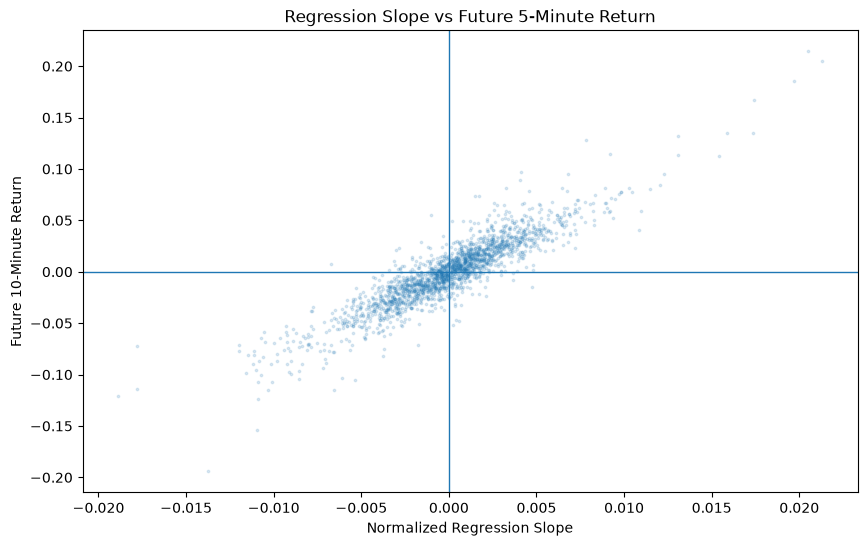

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    research["normalized_slope"],
    research["future_return_10m"],
    s=3,
    alpha=0.15
)

plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

plt.xlabel("Normalized Regression Slope")
plt.ylabel("Future 10-Minute Return")
plt.title("Regression Slope vs Future 5-Minute Return")

plt.show()